#Cell 1 — SAMPLE: Import Library

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from IPython.display import display, HTML

SEED = 42
from transformers import set_seed
set_seed(SEED)
np.random.seed(SEED)
print("Environment ready")

Environment ready


#Cell 2 — SAMPLE: Load Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/PI_Nasywa Dina Natania_51422209/Dataset/scrapped_TikTok_EN.csv"
df = pd.read_csv(DATA_PATH)

if "at" in df.columns:
    df = df[["content","score","at"]].dropna(subset=["content","score"])
else:
    df = df[["content","score"]].dropna(subset=["content","score"])

def score_to_sentiment(score):
    s = int(score)
    if s <= 2: return "negative"
    if s == 3: return "neutral"
    return "positive"
df["sentiment"] = df["score"].apply(score_to_sentiment)

df["content"] = (
    df["content"].astype(str).str.strip()
    .str.replace(r"http\S+|www\.\S+"," ", regex=True)
    .str.replace(r"@\w+"," ", regex=True)
    .str.replace(r"\s+"," ", regex=True)
)
before = len(df)
df = df.drop_duplicates(subset=["content"])
print(f"Dedup: {before} -> {len(df)}")

# Sampling 12k data
SAMPLE_N = 12000
if len(df) > SAMPLE_N:
    idx, _ = train_test_split(
        np.arange(len(df)),
        train_size=SAMPLE_N,
        stratify=df["sentiment"],
        random_state=SEED
    )
    df = df.iloc[idx].reset_index(drop=True)

print("Final shape:", df.shape)
print("Distribusi sentiment:\n", df["sentiment"].value_counts())
df.head()

Mounted at /content/drive
Dedup: 72000 -> 71777
Final shape: (12000, 4)
Distribusi sentiment:
 sentiment
positive    6680
negative    3960
neutral     1360
Name: count, dtype: int64


,content,score,at,sentiment
0,Just a great app to explore and make friends a...,5,2023-03-03 15:14:28,positive
1,Hate this app 🤬 everything is so strict plz I ...,1,2024-06-21 15:33:21,negative
2,Dkdn. Dk bad b hd ndjekejrnfnfnnf it was the s...,1,2021-10-27 03:44:05,negative
3,I HATE TIKTOK MY ACCOUNT IS NOW DELETED UGH I ...,1,2024-08-30 10:02:56,negative
4,Please i give you that five stars if you fasti...,5,2020-04-21 17:17:25,positive


#Cell 3 —  SAMPLE: Tabel Sampling

In [ ]:
df_view = df.copy()
if "at" in df_view.columns:
    df_view = df_view.rename(columns={"at":"created_at"})
else:
    df_view["created_at"] = pd.NaT
df_view = df_view.rename(columns={"content":"full_text"})

sampling_preview = df_view[["full_text","created_at"]].head(5).copy()
display(HTML(sampling_preview.to_html(index=False, border=1)))
print(f"Preview {len(sampling_preview)} baris dari total {len(df_view)} data")

full_text,created_at
Just a great app to explore and make friends and have fun making contents and sharing it to others,2023-03-03 15:14:28
Hate this app 🤬 everything is so strict plz I just had a mistake I have to wait 4 days to redownload my info hate u TikTok not a good app for me,2024-06-21 15:33:21
Dkdn. Dk bad b hd ndjekejrnfnfnnf it was the same as last week and now I can't wait for this week and we can 🥫 it seems to have worked out great day I y my way o is the same as we u is the one I can't get my phone to my phone is my favorite but it's a bit of a long week we can do that as well as the one 🕐 my favorite songs about being in my favorite son offs for kids and they have worked out for kids for kids to have a bit more of my phone to the one I got is a bit better 😃😃😃😃☺️😃☺️☺️ i,2021-10-27 03:44:05
I HATE TIKTOK MY ACCOUNT IS NOW DELETED UGH I HATE TIKTOK,2024-08-30 10:02:56
Please i give you that five stars if you fasting download and please give me chance to download this app i love that app i like it pleasree😭😭😭😭😭😭😭😭😭😭😭😭😭😭😭😭😭😭😭😭,2020-04-21 17:17:25


Preview 5 baris dari total 12000 data


# Cell 4 — EXPLORE: Distribusi Panjang Teks

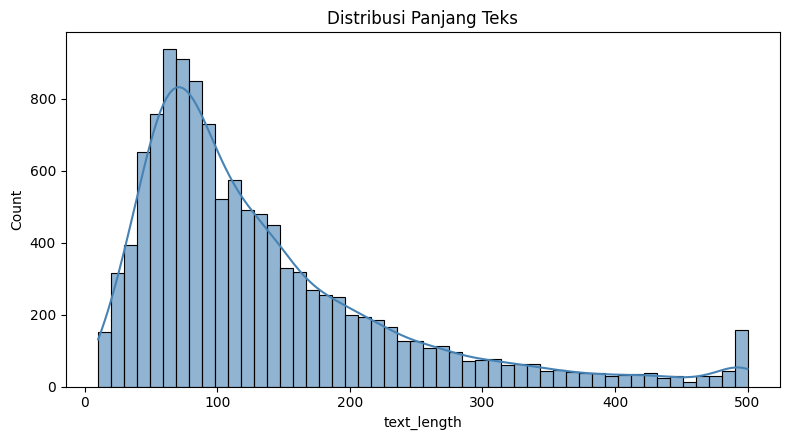

In [ ]:
def _clean_len(s):
    s = str(s).lower()
    s = re.sub(r"\s+"," ",s).strip()
    return s

df_len = df_view.copy()
df_len["cf_text"] = df_len["full_text"].apply(_clean_len)
df_len["length"] = df_len["cf_text"].str.len()

clip_max = 500
clip_len = df_len["length"].clip(upper=clip_max)

plt.figure(figsize=(8,4.5))
sns.histplot(clip_len, bins=50, kde=True, color="steelblue", alpha=0.6)
plt.title("Distribusi Panjang Teks")
plt.xlabel("text_length")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Cell 5 — EXPLORE: Distribusi Sentimen

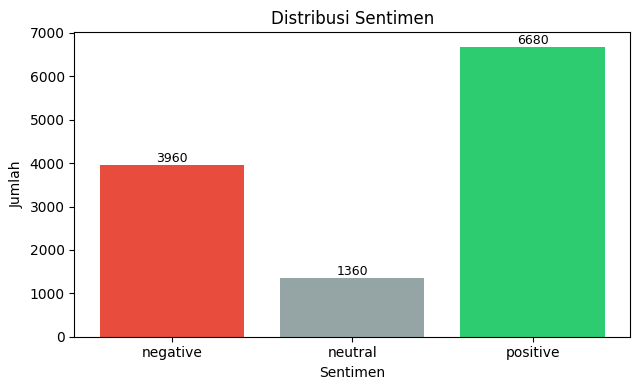

Ringkas distribusi:
 sentiment
negative    3960
neutral     1360
positive    6680
Name: count, dtype: int64


In [ ]:
counts = df["sentiment"].value_counts().sort_index()
labels = counts.index.tolist()
values = counts.values.tolist()
colors = ["#e74c3c","#95a5a6","#2ecc71"]

plt.figure(figsize=(6.5,4))
plt.bar(labels, values, color=colors)
plt.title("Distribusi Sentimen")
plt.xlabel("Sentimen"); plt.ylabel("Jumlah")
for i,v in enumerate(values):
    plt.text(i, v, str(v), ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

print("Ringkas distribusi:\n", counts)

# Cell 6 — EXPLORE: WordCloud per kelas

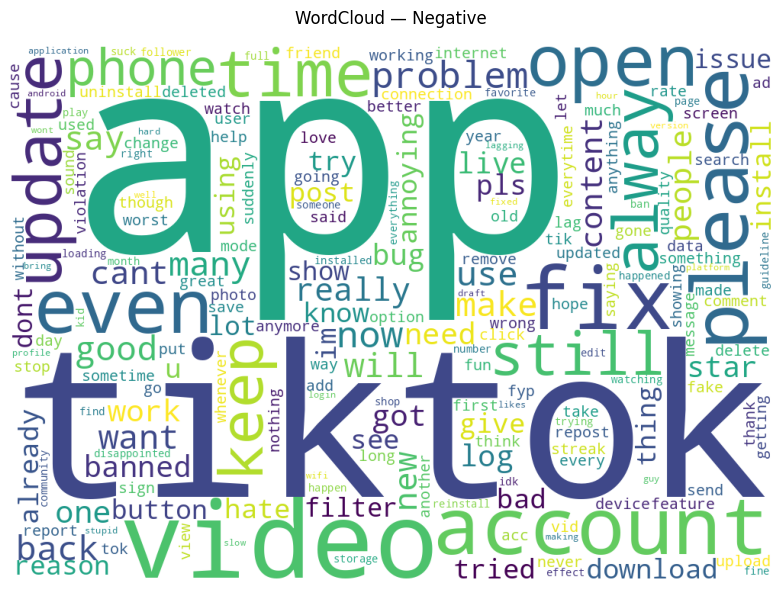

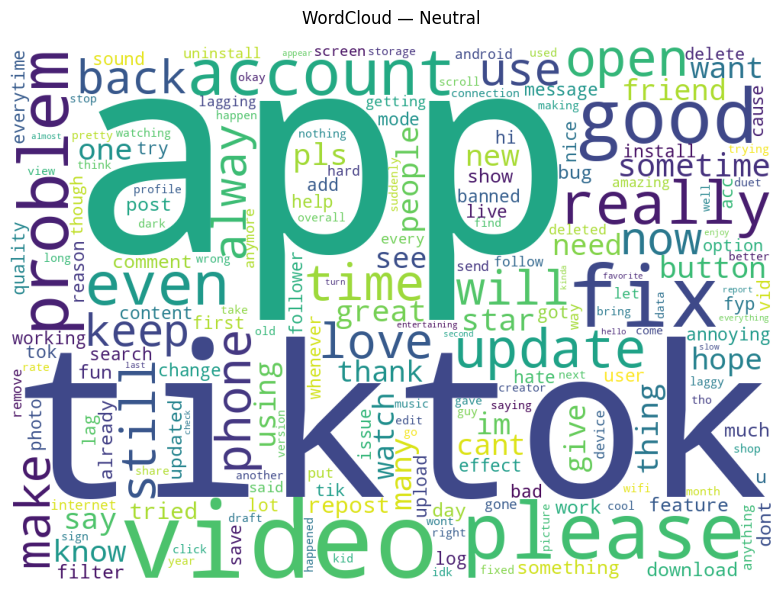

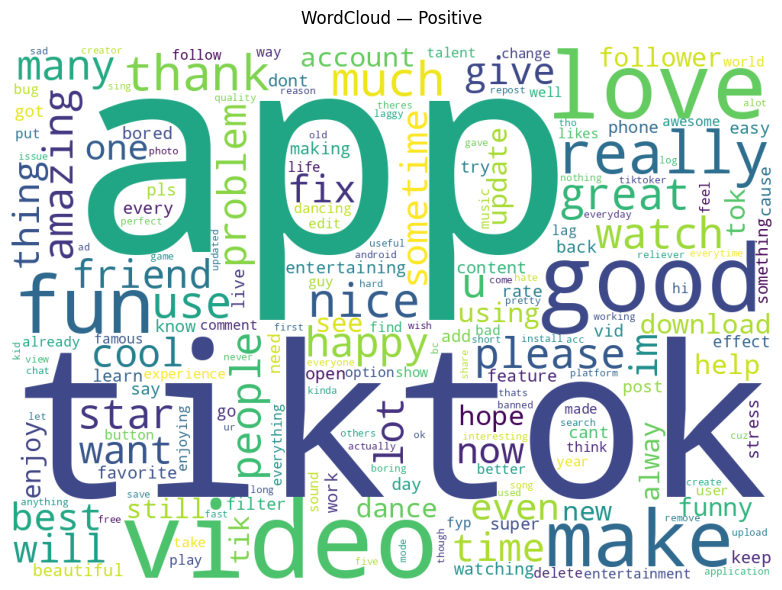

In [ ]:
!pip -q install wordcloud
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import os, re

os.makedirs("eda_plots", exist_ok=True)

def clean_text_wc(s: str):
    s = str(s).lower()
    s = re.sub(r"http\S+|www\.\S+", " ", s)
    s = re.sub(r"@\w+", " ", s)
    s = re.sub(r"<[^>]+>", " ", s)
    s = re.sub(r"[^\x00-\x7F]+", " ", s)
    s = re.sub(r"[^a-z0-9\s']", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

def show_wc(label: str, gap_px: int = 40):
    text = " ".join(df.loc[df["sentiment"] == label, "content"].astype(str).map(clean_text_wc).tolist())
    wc = WordCloud(width=1000, height=700, background_color="white",
                   stopwords=STOPWORDS, collocations=False, normalize_plurals=True,
                   random_state=42).generate(text)
    plt.figure(figsize=(10,6))
    plt.imshow(wc)
    plt.axis("off")
    plt.title(f"WordCloud — {label.title()}", pad=16)
    plt.tight_layout()
    plt.savefig(f"eda_plots/wordcloud_{label}.png", dpi=180)
    plt.show()
    # tambahkan gap antar kelas
    display(HTML(f"<div style='height:{gap_px}px'></div>"))

# tampilkan berurutan dengan gap
for lab in ["negative", "neutral", "positive"]:
    show_wc(lab)

#Cell 7 — MODIFY: Case Folding

In [ ]:
df_case = df_view[["full_text"]].head(5).copy()
df_case["before_case_folding"] = df_case["full_text"]
df_case["after_case_folding"]  = df_case["full_text"].str.lower()
display(df_case[["before_case_folding","after_case_folding"]])

,before_case_folding,after_case_folding
0,Just a great app to explore and make friends a...,just a great app to explore and make friends a...
1,Hate this app 🤬 everything is so strict plz I ...,hate this app 🤬 everything is so strict plz i ...
2,Dkdn. Dk bad b hd ndjekejrnfnfnnf it was the s...,dkdn. dk bad b hd ndjekejrnfnfnnf it was the s...
3,I HATE TIKTOK MY ACCOUNT IS NOW DELETED UGH I ...,i hate tiktok my account is now deleted ugh i ...
4,Please i give you that five stars if you fasti...,please i give you that five stars if you fasti...


# Cell 8 — MODIFY: Cleaning

In [ ]:
def clean_text(s: str) -> str:
    s = str(s).lower()
    s = re.sub(r"http\S+|www\.\S+"," ",s)
    s = re.sub(r"@\w+"," ",s)
    s = re.sub(r"<[^>]+>"," ",s)
    s = re.sub(r"[^\x00-\x7F]+"," ",s)
    s = re.sub(r"[^a-z0-9\s']"," ",s)
    s = re.sub(r"\s+"," ",s).strip()
    return s

df_view["clean_text"] = df_view["full_text"].apply(clean_text)

df_clean_prev = df_view[["full_text","clean_text"]].head(5).copy()
display(df_clean_prev)

,full_text,clean_text
0,Just a great app to explore and make friends a...,just a great app to explore and make friends a...
1,Hate this app 🤬 everything is so strict plz I ...,hate this app everything is so strict plz i ju...
2,Dkdn. Dk bad b hd ndjekejrnfnfnnf it was the s...,dkdn dk bad b hd ndjekejrnfnfnnf it was the sa...
3,I HATE TIKTOK MY ACCOUNT IS NOW DELETED UGH I ...,i hate tiktok my account is now deleted ugh i ...
4,Please i give you that five stars if you fasti...,please i give you that five stars if you fasti...


# Cell 9 — MODIFY: Tokenizing

In [ ]:
from transformers import BertTokenizerFast
tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")

def tokenize_to_list(text):
    return tokenizer.tokenize(str(text))

df_tok_prev = df_view[["full_text"]].head(5).copy()
df_tok_prev["tokens"] = df_tok_prev["full_text"].apply(tokenize_to_list)
display(df_tok_prev[["full_text","tokens"]])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

,full_text,tokens
0,Just a great app to explore and make friends a...,"[just, a, great, app, to, explore, and, make, ..."
1,Hate this app 🤬 everything is so strict plz I ...,"[hate, this, app, [UNK], everything, is, so, s..."
2,Dkdn. Dk bad b hd ndjekejrnfnfnnf it was the s...,"[d, ##k, ##d, ##n, ., d, ##k, bad, b, hd, n, #..."
3,I HATE TIKTOK MY ACCOUNT IS NOW DELETED UGH I ...,"[i, hate, ti, ##kt, ##ok, my, account, is, now..."
4,Please i give you that five stars if you fasti...,"[please, i, give, you, that, five, stars, if, ..."


# Cell 10 — MODIFY: Stopword Removal

In [ ]:
import nltk
from nltk.corpus import stopwords
try:
    stopwords.words("english")
except:
    nltk.download("stopwords")
STOPWORDS = set(stopwords.words("english"))

def remove_stop(tokens):
    return [t for t in tokens if t.lower() not in STOPWORDS and t.strip()]

df_stop_prev = df_tok_prev.copy()
df_stop_prev["tokens_no_stop"] = df_stop_prev["tokens"].apply(remove_stop)
display(df_stop_prev[["tokens","tokens_no_stop"]])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,tokens,tokens_no_stop
0,"[just, a, great, app, to, explore, and, make, ...","[great, app, explore, make, friends, fun, maki..."
1,"[hate, this, app, [UNK], everything, is, so, s...","[hate, app, [UNK], everything, strict, pl, ##z..."
2,"[d, ##k, ##d, ##n, ., d, ##k, bad, b, hd, n, #...","[##k, ##d, ##n, ., ##k, bad, b, hd, n, ##d, ##..."
3,"[i, hate, ti, ##kt, ##ok, my, account, is, now...","[hate, ti, ##kt, ##ok, account, deleted, u, ##..."
4,"[please, i, give, you, that, five, stars, if, ...","[please, give, five, stars, fast, ##ing, downl..."


# Cell 11 — MODIFY: Labeling

In [ ]:
df_label_prev = df_view.copy()
df_label_prev["label"] = df["sentiment"].astype(str)
df_label_prev = df_label_prev.head(5).merge(
    df_stop_prev[["tokens_no_stop"]].reset_index(drop=True),
    left_index=True, right_index=True, how="left"
)
display(df_label_prev[["label","tokens_no_stop"]])

,label,tokens_no_stop
0,positive,"[great, app, explore, make, friends, fun, maki..."
1,negative,"[hate, app, [UNK], everything, strict, pl, ##z..."
2,negative,"[##k, ##d, ##n, ., ##k, bad, b, hd, n, ##d, ##..."
3,negative,"[hate, ti, ##kt, ##ok, account, deleted, u, ##..."
4,positive,"[please, give, five, stars, fast, ##ing, downl..."


# Cell 12 — MODEL: Split Train/Val/Test 80:10:10

In [ ]:
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    df["content"].tolist(),
    df["sentiment"].tolist(),
    test_size=0.2,
    stratify=df["sentiment"],
    random_state=SEED
)

val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts,
    temp_labels,
    test_size=0.5,
    stratify=temp_labels,
    random_state=SEED
)

print(f"Train: {len(train_texts)} | Val: {len(val_texts)} | Test: {len(test_texts)}")

Train: 9600 | Val: 1200 | Test: 1200


# Cell 13 — MODEL: Tokenizer

In [ ]:
from transformers import BertTokenizerFast
from datasets import Dataset

label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}

tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")
MAX_LEN = 192

def encode_batch(texts):
    return tokenizer(texts, truncation=True, padding=True, max_length=MAX_LEN)

train_enc = encode_batch(train_texts)
val_enc   = encode_batch(val_texts)
test_enc  = encode_batch(test_texts)

train_labels_enc = [label2id[x] for x in train_labels]
val_labels_enc   = [label2id[x] for x in val_labels]
test_labels_enc  = [label2id[x] for x in test_labels]

train_dataset = Dataset.from_dict({
    "input_ids": train_enc["input_ids"],
    "attention_mask": train_enc["attention_mask"],
    "labels": train_labels_enc,
})
val_dataset = Dataset.from_dict({
    "input_ids": val_enc["input_ids"],
    "attention_mask": val_enc["attention_mask"],
    "labels": val_labels_enc,
})
test_dataset = Dataset.from_dict({
    "input_ids": test_enc["input_ids"],
    "attention_mask": test_enc["attention_mask"],
    "labels": test_labels_enc,
})

from transformers import DataCollatorWithPadding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("Tokenisasi & dataset siap.")

Tokenisasi & dataset siap.


# Cell 14 — MODEL: Class Weights & Metrics

In [ ]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score

classes = np.array([0, 1, 2])
train_y = np.array(train_labels_enc)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_y
)
class_weights = torch.tensor(class_weights, dtype=torch.float)
class_weights[1] = class_weights[1] * 1.2
print("Class weights:", class_weights.tolist())

def compute_metrics(eval_pred):
    logits = eval_pred.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    y_pred = logits.argmax(axis=-1)
    y_true = eval_pred.label_ids
    acc = float((y_pred == y_true).mean())
    f1_macro = f1_score(y_true, y_pred, average="macro")
    f1_weighted = f1_score(y_true, y_pred, average="weighted")
    return {"accuracy": acc, "f1_macro": f1_macro, "f1_weighted": f1_weighted}

Class weights: [1.0101009607315063, 3.529411792755127, 0.598802387714386]


# Cell 15 — MODEL: Weighted Trainer

In [ ]:
import torch
import torch.nn.functional as F
from transformers import Trainer

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, focal_gamma=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights if class_weights is not None else torch.ones(3, dtype=torch.float)
        self.focal_gamma = focal_gamma

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.get("labels")
        model_inputs = {k: v for k, v in inputs.items() if k != "labels"}

        outputs = model(**model_inputs)
        logits = outputs.logits

        lsf = getattr(self.args, "label_smoothing_factor", 0.0)

        if self.focal_gamma is None:
            loss = F.cross_entropy(
                logits, labels,
                weight=self.class_weights.to(logits.device),
                label_smoothing=lsf
            )
        else:
            ce = F.cross_entropy(
                logits, labels,
                weight=self.class_weights.to(logits.device),
                label_smoothing=lsf,
                reduction="none"
            )
            pt = torch.exp(-ce)
            loss = ((1 - pt) ** self.focal_gamma * ce).mean()

        return (loss, outputs) if return_outputs else loss

# Cell 16 — MODEL: Inisialisasi Model & Training

In [ ]:
from transformers import BertForSequenceClassification, TrainingArguments, EarlyStoppingCallback

model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=3,
    id2label=id2label,
    label2id=label2id,
)

training_args = TrainingArguments(
    output_dir="./outputs",
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    num_train_epochs=10,
    learning_rate=2e-5,
    weight_decay=0.01,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    warmup_ratio=0.1,
    fp16=True,
    logging_steps=100,
    label_smoothing_factor=0.05,
    report_to=[],
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    class_weights=class_weights,
    focal_gamma=None,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

train_output = trainer.train()
print("Selesai training. Best model telah dimuat.")

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-2442401185.py:7: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `WeightedTrainer.__init__`. Use `processing_class` instead.
  super().__init__(*args, **kwargs)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
1,0.843600,0.855303,0.665833,0.612203,0.716922
2,0.824100,0.846623,0.716667,0.639951,0.747399
3,0.680800,0.907898,0.769167,0.663549,0.779372
4,0.584600,1.048693,0.777500,0.644809,0.772209
5,0.469300,1.096233,0.731667,0.637291,0.750956


Selesai training. Best model telah dimuat.


# Cell 17 — ASSESS: Evaluasi di Test Set

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

pred_test = trainer.predict(test_dataset)
y_true = np.array(test_dataset["labels"])
y_pred = np.argmax(pred_test.predictions, axis=-1)

print("=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=["negative","neutral","positive"]))
print("Accuracy:", accuracy_score(y_true, y_pred))

=== Classification Report ===
              precision    recall  f1-score   support

    negative       0.79      0.75      0.77       396
     neutral       0.28      0.34      0.31       136
    positive       0.89      0.88      0.89       668

    accuracy                           0.78      1200
   macro avg       0.65      0.66      0.65      1200
weighted avg       0.79      0.78      0.78      1200

Accuracy: 0.7766666666666666


# Cell 18 — ASSESS: Confusion Matrix

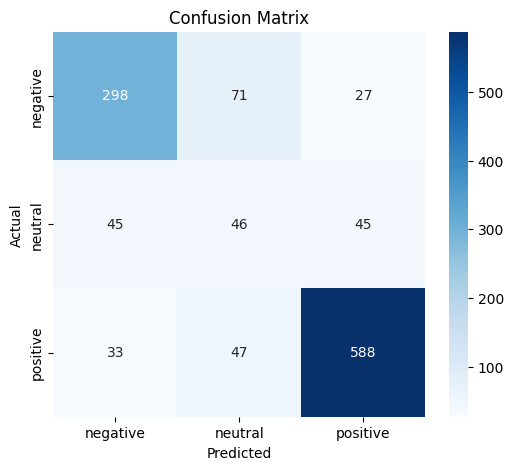

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["negative","neutral","positive"],
            yticklabels=["negative","neutral","positive"],
            cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Cell 19 — ASSESS: Uji Model

In [ ]:
import re, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

CKPT_DIR = "./outputs"
try:
    tok_inf = AutoTokenizer.from_pretrained(CKPT_DIR)
    mdl_inf = AutoModelForSequenceClassification.from_pretrained(CKPT_DIR)
except Exception:
    tok_inf = tokenizer
    mdl_inf = trainer.model

device = "cuda" if torch.cuda.is_available() else "cpu"
mdl_inf = mdl_inf.to(device).eval()

def _clean_infer(t: str) -> str:
    if "clean_text" in globals() and callable(clean_text):
        return clean_text(t)
    return re.sub(r"\s+", " ", str(t)).strip().lower()

id2label_cfg = getattr(mdl_inf.config, "id2label", None)
if id2label_cfg:
    id2label_final = {int(k): v for k, v in id2label_cfg.items()}
else:
    id2label_final = {0: "negative", 1: "neutral", 2: "positive"}

MAXLEN = MAX_LEN if "MAX_LEN" in globals() else 192

print("\n--- Uji Coba Model dengan Komentar Baru ---")
while True:
    try:
        txt = input("Masukkan komentar (ketik 'quit' untuk keluar): ").strip()
    except EOFError:
        print("\n(Input interaktif tidak tersedia di lingkungan ini.)")
        break

    if txt.lower() in {"quit", "q", "exit"}:
        print("Keluar dari uji coba.")
        break
    if not txt:
        print("Teks kosong, silakan masukkan komentar.")
        continue

    raw = txt
    txt = _clean_infer(txt)

    enc = tok_inf([txt], return_tensors="pt",
                  truncation=True, padding=True, max_length=MAXLEN)
    enc = {k: v.to(device) for k, v in enc.items()}

    with torch.no_grad():
        logits = mdl_inf(**enc).logits
        probs = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()
        pred_id = int(probs.argmax())
        pred_lab = id2label_final[pred_id]
        conf = float(probs[pred_id])

    print(f"Komentar          : {raw}")
    print(f"Prediksi Sentimen : {pred_lab}")
    print(f"Skor Kepercayaan  : {conf:.4f}")
    print("-" * 40)


--- Uji Coba Model dengan Komentar Baru ---
Masukkan komentar (ketik 'quit' untuk keluar): the app is really good, smooth performance, very useful
Komentar          : the app is really good, smooth performance, very useful
Prediksi Sentimen : positive
Skor Kepercayaan  : 0.8225
----------------------------------------
Masukkan komentar (ketik 'quit' untuk keluar): i installed it yesterday, still checking the features
Komentar          : i installed it yesterday, still checking the features
Prediksi Sentimen : neutral
Skor Kepercayaan  : 0.4757
----------------------------------------
Masukkan komentar (ketik 'quit' untuk keluar): too many bugs, slow response, not recommended
Komentar          : too many bugs, slow response, not recommended
Prediksi Sentimen : negative
Skor Kepercayaan  : 0.8879
----------------------------------------
Masukkan komentar (ketik 'quit' untuk keluar): quit
Keluar dari uji coba.
